# PyTorch Mask R-CNN Training for Image Forgery Detection

This notebook trains a Mask R-CNN model using PyTorch's torchvision to detect and segment forged regions in images.

## Overview
- **Model**: Mask R-CNN with ResNet-50 FPN backbone
- **Task**: Instance segmentation of forged regions
- **Dataset**: Forged images with corresponding mask files (.npy)

## Requirements
- torch
- torchvision
- numpy
- PIL/Pillow
- matplotlib
- tqdm


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [1]:
!nvidia-smi

Wed Dec  3 10:02:28 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 571.59                 Driver Version: 571.59         CUDA Version: 12.8     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX 5000 Ada Gene...  WDDM  |   00000000:01:00.0  On |                  Off |
| 30%   29C    P8              8W /  250W |    1038MiB /  32760MiB |      7%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
#upload your kaggle.json API key from kaggle.
from google.colab import files
files.upload()

In [ ]:
!mkdir -p /root/.config/kaggle
!mv kaggle.json /root/.config/kaggle

In [ ]:
!kaggle competitions download -c recodai-luc-scientific-image-forgery-detection
!unzip /content/recodai-luc-scientific-image-forgery-detection.zip

In [ ]:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121
%pip install numpy
%pip install Pillow
%pip install matplotlib
%pip install tqdm

## 1. Imports and Setup


In [21]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from tqdm import tqdm
import json
from datetime import datetime

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA Version: {torch.version.cuda}")


Using device: cuda
GPU: NVIDIA RTX 5000 Ada Generation
CUDA Version: 12.1


## 2. Dataset Configuration


In [22]:
# Dataset paths
DATA_DIR = "recodai-luc-scientific-image-forgery-detection"
FORGED_DIR = os.path.join(DATA_DIR, "train_images", "forged")
MASK_DIR = os.path.join(DATA_DIR, "train_masks")

# Verify paths exist
print(f"Forged images directory: {FORGED_DIR}")
print(f"Exists: {os.path.exists(FORGED_DIR)}")
print(f"\nMask directory: {MASK_DIR}")
print(f"Exists: {os.path.exists(MASK_DIR)}")

if os.path.exists(FORGED_DIR):
    num_forged = len([f for f in os.listdir(FORGED_DIR) if f.endswith(('.png', '.jpg', '.jpeg'))])
    print(f"\nNumber of forged images: {num_forged}")

if os.path.exists(MASK_DIR):
    num_masks = len([f for f in os.listdir(MASK_DIR) if f.endswith('.npy')])
    print(f"Number of mask files: {num_masks}")


Forged images directory: recodai-luc-scientific-image-forgery-detection\train_images\forged
Exists: True

Mask directory: recodai-luc-scientific-image-forgery-detection\train_masks
Exists: True

Number of forged images: 2751
Number of mask files: 2751


## 3. Dataset Class


In [23]:
from torch.utils.data import Dataset
from torchvision import transforms

class ForgeryDataset(Dataset):
    """PyTorch Dataset for image forgery detection with masks."""

    def __init__(self, forged_dir, mask_dir, transform=None, train=True, do_rotate=False, rotation_degrees=15):
        """
        Args:
            forged_dir: Path to directory containing forged images
            mask_dir: Path to directory containing mask files (.npy)
            transform: Optional transform to be applied to images
            train: If True, use training split (80%), else validation (20%)
            do_rotate: If True, apply random rotation to images and masks.
            rotation_degrees: Max degrees for random rotation (e.g., 15 for -15 to +15).
        """
        self.forged_dir = forged_dir
        self.mask_dir = mask_dir
        self.transform = transform
        self.train = train
        self.do_rotate = do_rotate
        self.rotation_degrees = rotation_degrees

        # Get all forged images
        self.image_files = [f for f in os.listdir(forged_dir)
                           if f.endswith(('.png', '.jpg', '.jpeg'))]

        # 80/20 train/val split
        np.random.seed(42)
        np.random.shuffle(self.image_files)
        split_idx = int(len(self.image_files) * 0.8)

        if train:
            self.image_files = self.image_files[:split_idx]
        else:
            self.image_files = self.image_files[split_idx:]

        print(f"Loaded {len(self.image_files)} {'training' if train else 'validation'} images")

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        # Load image
        img_path = os.path.join(self.forged_dir, self.image_files[idx])
        image = Image.open(img_path).convert('RGB')

        # Get base name for mask
        base_name = os.path.splitext(self.image_files[idx])[0]
        mask_path = os.path.join(self.mask_dir, f"{base_name}.npy")

        # Load mask
        if os.path.exists(mask_path):
            mask_array_initial = np.load(mask_path)

            # Handle different mask shapes
            if len(mask_array_initial.shape) == 3:
                if mask_array_initial.shape[0] == 1: # Case: (1, H, W)
                    mask_array = mask_array_initial[0, :, :]
                elif mask_array_initial.shape[2] == 1: # Case: (H, W, 1)
                    mask_array = mask_array_initial[:, :, 0]
                else: # Fallback for other 3D cases (e.g., (H, W, C) where C > 1), sum channels
                    mask_array = mask_array_initial.sum(axis=2)
            else:
                mask_array = mask_array_initial

            mask_array = (mask_array > 0).astype(np.uint8)

        else:
            # No mask found - create empty mask
            mask_array = np.zeros((image.size[1], image.size[0]), dtype=np.uint8)

        # Resize mask to match image if needed
        if mask_array.shape[:2] != (image.size[1], image.size[0]):
            mask_pil = Image.fromarray(mask_array)
            mask_pil = mask_pil.resize((image.size[0], image.size[1]), Image.NEAREST)
            mask_array = np.array(mask_pil)

        mask_pil = Image.fromarray(mask_array, mode='L') # Convert mask to PIL for rotation

        # Apply random rotation if enabled for training
        if self.do_rotate and self.train:
            angle = np.random.uniform(-self.rotation_degrees, self.rotation_degrees)
            image = image.rotate(angle, resample=Image.BILINEAR, expand=True, fillcolor=0)
            mask_pil = mask_pil.rotate(angle, resample=Image.NEAREST, expand=True, fillcolor=0)

        # Convert rotated mask back to numpy array
        mask_array = np.array(mask_pil)

        # Convert to tensor
        if self.transform:
            image = self.transform(image)
        else:
            # Default transform: convert to tensor
            image = transforms.ToTensor()(image)

        # Prepare targets for Mask R-CNN
        # Mask R-CNN expects:
        # - boxes: [N, 4] in (x1, y1, x2, y2) format
        # - labels: [N] class labels (1 = forged_region)
        # - masks: [N, H, W] binary masks

        # Find bounding box from mask
        rows = np.any(mask_array, axis=1)
        cols = np.any(mask_array, axis=0)

        if np.any(mask_array):
            y_min, y_max = np.where(rows)[0][[0, -1]]
            x_min, x_max = np.where(cols)[0][[0, -1]]

            # Convert to (x1, y1, x2, y2) format
            boxes = torch.tensor([[x_min, y_min, x_max, y_max]], dtype=torch.float32)
            labels = torch.tensor([1], dtype=torch.int64)  # 1 = forged_region
            masks = torch.tensor(mask_array[np.newaxis, :, :], dtype=torch.uint8)
        else:
            # No forged region - empty targets
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
            masks = torch.zeros((0, mask_array.shape[0], mask_array.shape[1]), dtype=torch.uint8)

        target = {
            'boxes': boxes,
            'labels': labels,
            'masks': masks,
        }

        return image, target

## 4. Create Datasets and Data Loaders


In [24]:
from torch.utils.data import DataLoader
from torchvision import transforms

# Create datasets
print("Loading datasets...")
# Define transforms
train_transform = transforms.ToTensor()
val_transform = transforms.ToTensor()

# Enable data augmentation for training to improve generalization
# Rotation augmentation helps model learn to detect forgery at different angles
train_dataset = ForgeryDataset(FORGED_DIR, MASK_DIR, transform=train_transform, train=True, do_rotate=True, rotation_degrees=15)
val_dataset = ForgeryDataset(FORGED_DIR, MASK_DIR, transform=val_transform, train=False, do_rotate=False)  # No augmentation for validation

# Custom collate function for batching
def collate_fn(batch):
    """Custom collate function for batching images and targets."""
    images = [item[0] for item in batch]
    targets = [item[1] for item in batch]
    return images, targets

# Training parameters
BATCH_SIZE = 2  # Adjust based on GPU memory
NUM_WORKERS = 0  # Adjust based on your system

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn
)

print(f"\nTrain batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

Loading datasets...
Loaded 2200 training images
Loaded 551 validation images

Train batches: 1100
Validation batches: 276


## 5.2. Ground Truth Mask Validation

In [25]:
def validate_ground_truth_masks(dataset, num_samples=10):
    """Validate that ground truth masks are properly loaded and formatted."""
    print("Validating ground truth masks...")
    print("=" * 60)
    
    issues = []
    valid_samples = 0
    
    for i in range(min(num_samples, len(dataset))):
        try:
            image, target = dataset[i]
            
            # Check image
            img_height, img_width = image.shape[1], image.shape[2]
            
            # Check masks
            num_masks = target['masks'].shape[0]
            num_boxes = target['boxes'].shape[0]
            
            if num_masks == 0:
                issues.append(f"Sample {i}: No masks found")
                continue
            
            # Check mask dimensions
            mask_shape = target['masks'].shape
            expected_shape = (num_masks, img_height, img_width)
            
            if mask_shape != expected_shape:
                issues.append(f"Sample {i}: Mask shape mismatch. Got {mask_shape}, expected {expected_shape}")
                continue
            
            # Check mask values (should be 0 or 1)
            mask_values = target['masks'].unique()
            if not all(v in [0, 1] for v in mask_values):
                issues.append(f"Sample {i}: Mask contains invalid values: {mask_values}")
                continue
            
            # Check bounding boxes
            if num_boxes != num_masks:
                issues.append(f"Sample {i}: Box count ({num_boxes}) != mask count ({num_masks})")
            
            # Check box coordinates are valid
            if num_boxes > 0:
                boxes = target['boxes']
                for j, box in enumerate(boxes):
                    x1, y1, x2, y2 = box
                    if x1 >= x2 or y1 >= y2:
                        issues.append(f"Sample {i}, Box {j}: Invalid box coordinates [{x1}, {y1}, {x2}, {y2}]")
                    if x1 < 0 or y1 < 0 or x2 > img_width or y2 > img_height:
                        issues.append(f"Sample {i}, Box {j}: Box out of bounds. Box: [{x1}, {y1}, {x2}, {y2}], Image: {img_width}x{img_height}")
            
            # Check mask coverage
            mask_sum = target['masks'].sum().item()
            total_pixels = img_height * img_width
            coverage = mask_sum / total_pixels
            
            if coverage < 0.001:
                issues.append(f"Sample {i}: Very low mask coverage ({coverage:.4%})")
            
            valid_samples += 1
            
        except Exception as e:
            issues.append(f"Sample {i}: Error - {str(e)}")
    
    print(f"Validated {valid_samples}/{min(num_samples, len(dataset))} samples")
    if issues:
        print(f"\n⚠️  Found {len(issues)} issues:")
        for issue in issues[:10]:  # Show first 10 issues
            print(f"  - {issue}")
        if len(issues) > 10:
            print(f"  ... and {len(issues) - 10} more issues")
    else:
        print("✓ All samples validated successfully!")
    
    print("=" * 60)
    return len(issues) == 0

# Validate training dataset
print("Validating TRAINING dataset:")
validate_ground_truth_masks(train_dataset, num_samples=20)

print("\nValidating VALIDATION dataset:")
validate_ground_truth_masks(val_dataset, num_samples=20)


Validating TRAINING dataset:
Validating ground truth masks...
Validated 20/20 samples
✓ All samples validated successfully!

Validating VALIDATION dataset:
Validating ground truth masks...
Validated 20/20 samples
✓ All samples validated successfully!


True

## 5. Visualize Sample Data

Let's check a sample image and mask to verify the dataset is loading correctly.


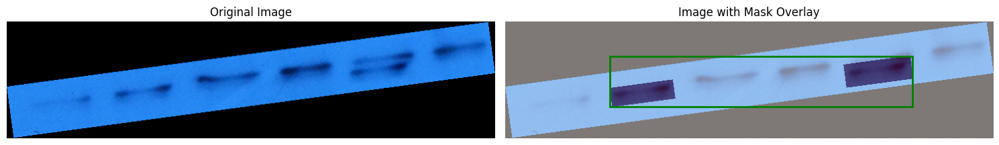

Image shape: (176, 737, 3)
Mask shape: (176, 737)
Bounding box: [158.  52. 615. 128.]


In [26]:
# Visualize a sample from the dataset
# For this dataset the first is 0 and last is 2199
sample_idx = 159
image, target = train_dataset[sample_idx]

# Convert image tensor to numpy for visualization
img_np = image.permute(1, 2, 0).cpu().numpy()
img_np = (img_np * 255).astype(np.uint8)

# Get mask
mask = target['masks'][0].numpy() if target['masks'].shape[0] > 0 else None
box = target['boxes'][0].numpy() if target['boxes'].shape[0] > 0 else None

# Plot
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].imshow(img_np)
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(img_np)
if mask is not None:
    axes[1].imshow(mask, alpha=0.5, cmap='Reds')
    if box is not None:
        rect = patches.Rectangle(
            (box[0], box[1]), box[2] - box[0], box[3] - box[1],
            linewidth=2, edgecolor='green', facecolor='none'
        )
        axes[1].add_patch(rect)
axes[1].set_title('Image with Mask Overlay')
axes[1].axis('off')

plt.tight_layout()
plt.show()

print(f"Image shape: {img_np.shape}")
print(f"Mask shape: {mask.shape if mask is not None else 'No mask'}")
print(f"Bounding box: {box if box is not None else 'No box'}")


## 11.1 Verify Data Loading for Multiple Samples

Visualizing 3 samples from the Training Dataset...


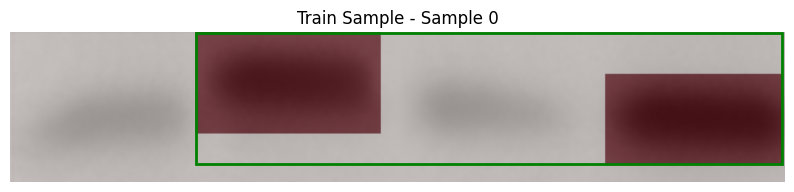

Image shape: (81, 418, 3)
Mask shape: (81, 418)
Bounding box: [100.   0. 416.  71.]


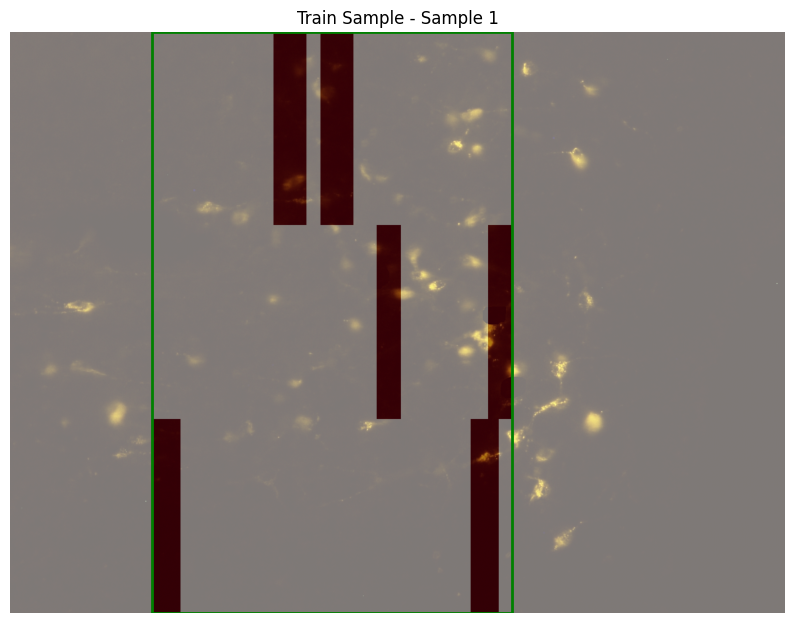

Image shape: (1200, 1600, 3)
Mask shape: (1200, 1600)
Bounding box: [ 293.    0. 1035. 1199.]


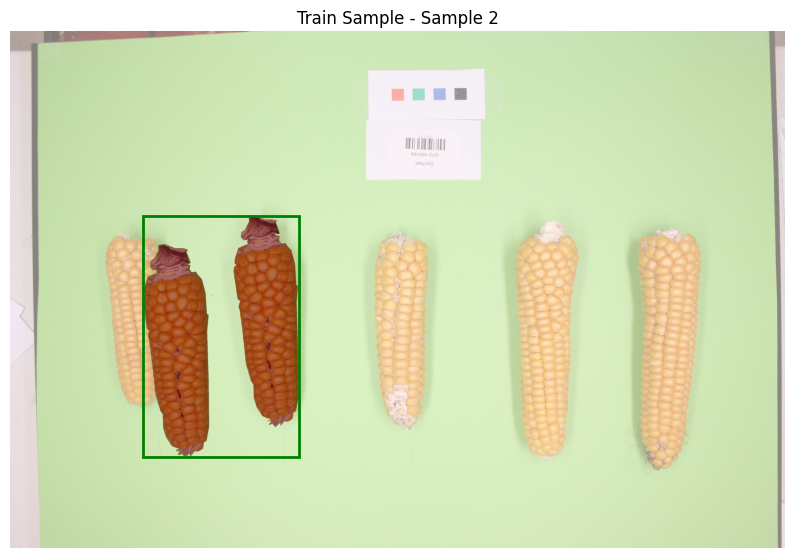

Image shape: (2592, 3888, 3)
Mask shape: (2592, 3888)
Bounding box: [ 666.  924. 1447. 2135.]

Visualizing 3 samples from the Validation Dataset...


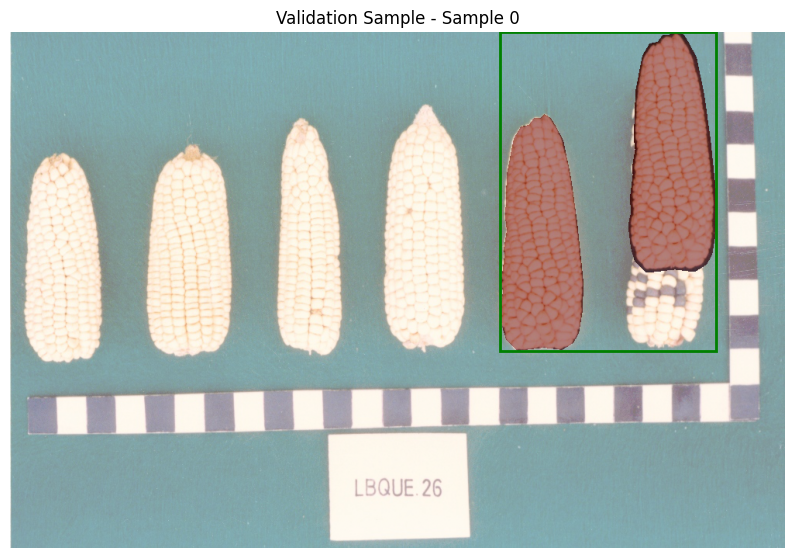

Image shape: (666, 1000, 3)
Mask shape: (666, 1000)
Bounding box: [632.   0. 911. 411.]


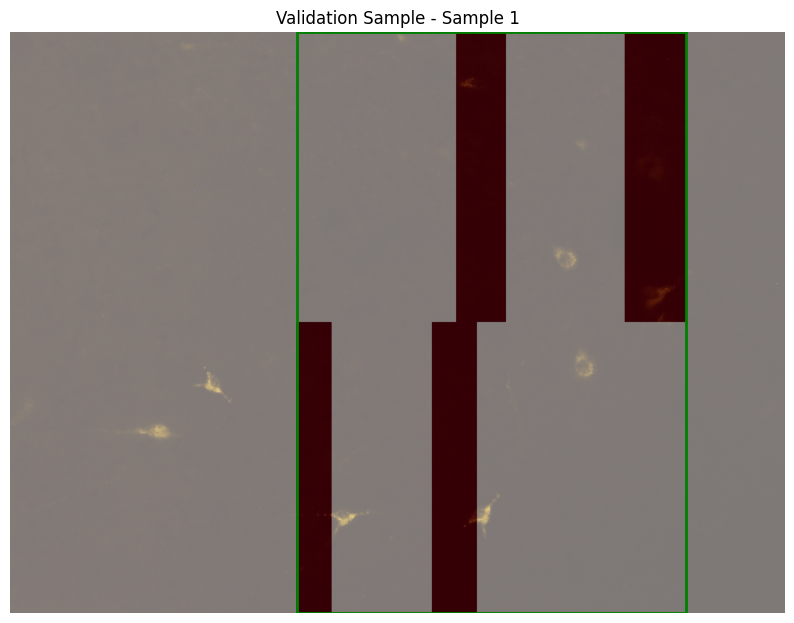

Image shape: (1200, 1600, 3)
Mask shape: (1200, 1600)
Bounding box: [ 591.    0. 1395. 1199.]


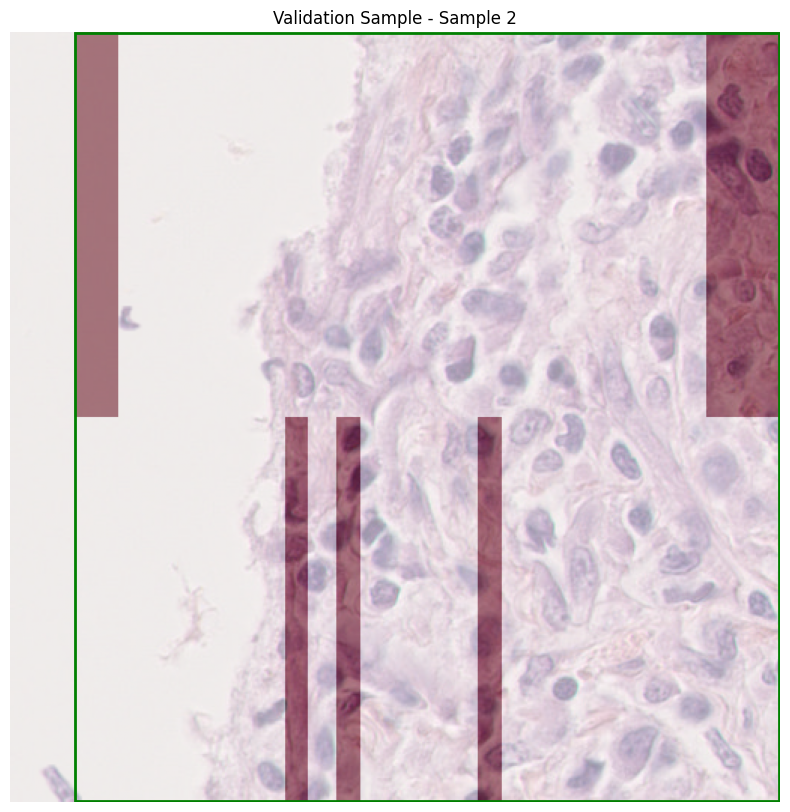

Image shape: (512, 512, 3)
Mask shape: (512, 512)
Bounding box: [ 43.   0. 511. 511.]


In [30]:
def visualize_sample(dataset, idx, title="Sample Visualization"):
    """Visualizes a single sample from the dataset with mask and bounding box.
    Args:
        dataset: The dataset to draw a sample from.
        idx: The index of the sample to visualize.
        title: Title for the plot.
    """
    image, target = dataset[idx]

    # Convert image tensor to numpy for visualization
    img_np = image.permute(1, 2, 0).cpu().numpy()
    img_np = (img_np * 255).astype(np.uint8)

    # Get mask and box
    mask = target['masks'][0].numpy() if target['masks'].shape[0] > 0 else None
    box = target['boxes'][0].numpy() if target['boxes'].shape[0] > 0 else None

    fig, ax = plt.subplots(1, 1, figsize=(10, 10))

    ax.imshow(img_np)
    if mask is not None:
        ax.imshow(mask, alpha=0.5, cmap='Reds')
    if box is not None:
        rect = patches.Rectangle(
            (box[0], box[1]), box[2] - box[0], box[3] - box[1],
            linewidth=2, edgecolor='green', facecolor='none'
        )
        ax.add_patch(rect)
    ax.set_title(f"{title} - Sample {idx}")
    ax.axis('off')
    plt.show()

    print(f"Image shape: {img_np.shape}")
    print(f"Mask shape: {mask.shape if mask is not None else 'No mask'}")
    print(f"Bounding box: {box if box is not None else 'No box'}")

# Visualize a few samples from the training dataset
print("Visualizing 3 samples from the Training Dataset...")
for i in range(3):
    visualize_sample(train_dataset, i, title="Train Sample")

# Visualize a few samples from the validation dataset
print("\nVisualizing 3 samples from the Validation Dataset...")
for i in range(3):
    visualize_sample(val_dataset, i, title="Validation Sample")


## 6. Model Setup


In [27]:
def get_model_instance_segmentation(num_classes):
    """Create a Mask R-CNN model with the specified number of classes.

    Args:
        num_classes: Number of classes (including background)
                     For forgery detection: 2 (background + forged_region)

    Returns:
        model: Mask R-CNN model
    """
    # Load pre-trained model
    model = maskrcnn_resnet50_fpn(pretrained=True)

    # Get number of input features for the classifier
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    # Replace the pre-trained head with a new one
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    # Get number of input features for the mask classifier
    in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
    hidden_layer = 256
    # Replace the mask predictor with a new one
    model.roi_heads.mask_predictor = MaskRCNNPredictor(
        in_features_mask,
        hidden_layer,
        num_classes
    )

    return model

# Create model
NUM_CLASSES = 2  # background + forged_region
print("Creating model...")
model = get_model_instance_segmentation(NUM_CLASSES)
model.to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Model created and moved to {device}")


Creating model...
Total parameters: 43,922,395
Trainable parameters: 43,699,995
Model created and moved to cuda


## 7. Training Functions


In [28]:
def train_one_epoch(model, optimizer, data_loader, device, epoch, print_freq=10, clip_grad_norm=1.0):
    """Train the model for one epoch with gradient monitoring and clipping."""
    model.train()
    metric_logger = {'loss': 0.0, 'loss_classifier': 0.0, 'loss_box_reg': 0.0,
                     'loss_mask': 0.0, 'loss_objectness': 0.0, 'loss_rpn_box_reg': 0.0}
    
    # Gradient monitoring
    grad_norms = []
    grad_max = []
    grad_mean = []

    pbar = tqdm(data_loader, desc=f'Epoch {epoch}')

    for batch_idx, (images, targets) in enumerate(pbar):
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        # Forward pass
        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        # Backward pass
        optimizer.zero_grad()
        losses.backward()
        
        # Gradient clipping and monitoring
        if clip_grad_norm > 0:
            grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad_norm)
            grad_norms.append(grad_norm.item())
        
        # Monitor gradients
        total_norm = 0
        max_grad = 0
        param_count = 0
        for p in model.parameters():
            if p.grad is not None:
                param_norm = p.grad.data.norm(2)
                total_norm += param_norm.item() ** 2
                max_grad = max(max_grad, p.grad.data.abs().max().item())
                param_count += 1
        
        if param_count > 0:
            total_norm = total_norm ** (1. / 2)
            grad_max.append(max_grad)
            grad_mean.append(total_norm)
        
        optimizer.step()

        # Update metrics
        metric_logger['loss'] += losses.item()
        for k, v in loss_dict.items():
            metric_logger[k] += v.item()

        # Update progress bar
        pbar.set_postfix({
            'loss': f"{losses.item():.4f}",
            'mask': f"{loss_dict['loss_mask'].item():.4f}",
            'grad': f"{grad_norm.item() if clip_grad_norm > 0 else 0:.3f}"
        })

    # Average metrics
    for k in metric_logger:
        metric_logger[k] /= len(data_loader)
    
    # Add gradient statistics
    if grad_norms:
        metric_logger['grad_norm_mean'] = np.mean(grad_norms)
        metric_logger['grad_norm_max'] = np.max(grad_norms)
    if grad_max:
        metric_logger['grad_max_mean'] = np.mean(grad_max)
        metric_logger['grad_max_max'] = np.max(grad_max)

    return metric_logger


# FIXED evaluate function - properly computes validation losses
def evaluate(model, data_loader, device):
    """Evaluate the model on validation set."""
    # Save original training state
    was_training = model.training
    
    # Set to train mode to get loss_dict (eval mode returns predictions)
    model.train()
    
    metric_logger = {'loss': 0.0, 'loss_classifier': 0.0, 'loss_box_reg': 0.0,
                     'loss_mask': 0.0, 'loss_objectness': 0.0, 'loss_rpn_box_reg': 0.0}
    
    num_batches = 0
    mask_losses = []  # Store individual mask losses for debugging

    with torch.no_grad():
        for batch_idx, (images, targets) in enumerate(tqdm(data_loader, desc='Evaluating')):
            images = [img.to(device) for img in images]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            # In train mode with targets, model returns loss_dict
            loss_dict = model(images, targets)

            # Check if loss_dict is actually a dict (should be)
            if isinstance(loss_dict, dict):
                losses = sum(loss for loss in loss_dict.values())
                metric_logger['loss'] += losses.item()
                
                # Accumulate each loss component
                for k, v in loss_dict.items():
                    if k in metric_logger:
                        loss_value = v.item()
                        metric_logger[k] += loss_value
                        # Store mask losses for debugging
                        if k == 'loss_mask':
                            mask_losses.append(loss_value)
                    else:
                        # Handle unexpected keys
                        if k not in metric_logger:
                            metric_logger[k] = 0.0
                        metric_logger[k] += v.item()
                
                num_batches += 1
            else:
                # If it's not a dict, something went wrong
                print(f"Warning: Expected dict, got {type(loss_dict)}")
                continue

    # Average metrics by number of batches (consistent with training)
    if num_batches > 0:
        for k in metric_logger:
            metric_logger[k] /= num_batches
        
        # Debug: Check if mask losses are varying
        if len(mask_losses) > 1:
            mask_loss_std = np.std(mask_losses)
            if mask_loss_std < 1e-6:
                print(f"⚠️  Warning: Mask loss has very low variance (std={mask_loss_std:.2e})")
                print(f"   Mask loss range: [{min(mask_losses):.6f}, {max(mask_losses):.6f}]")
    
    # Restore original training state
    model.train(was_training)

    return metric_logger

print("✓ Fixed evaluate function loaded! This properly computes validation losses.")
print("Added debugging to detect if mask losses are not varying between batches.")


✓ Fixed evaluate function loaded! This properly computes validation losses.
Added debugging to detect if mask losses are not varying between batches.


## 8. Setup Optimizer and Learning Rate Scheduler


In [29]:
# Optimizer - Using better regularization to prevent overfitting
LEARNING_RATE = 0.005  # Slightly higher initial LR for faster convergence
params = [p for p in model.parameters() if p.requires_grad]
optimizer = optim.SGD(params, lr=LEARNING_RATE, momentum=0.9, weight_decay=0.001)  # Increased from 0.0005 to 0.001 for better regularization

# Better learning rate scheduler - ReduceLROnPlateau based on validation loss
# This will reduce LR when validation loss plateaus instead of fixed schedule
lr_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3, verbose=True, min_lr=1e-6
)

# Alternative: CosineAnnealingLR for smoother decay
# lr_scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20, eta_min=1e-6)

print(f"Optimizer: SGD with lr={LEARNING_RATE}, momentum=0.9, weight_decay=0.001")
print(f"LR Scheduler: ReduceLROnPlateau (factor=0.5, patience=3)")
print(f"Gradient clipping: Enabled (max_norm=1.0)")
print(f"Regularization: Increased weight_decay to 0.001 to reduce overfitting")


Optimizer: SGD with lr=0.005, momentum=0.9, weight_decay=0.001
LR Scheduler: ReduceLROnPlateau (factor=0.5, patience=3)
Gradient clipping: Enabled (max_norm=1.0)
Regularization: Increased weight_decay to 0.001 to reduce overfitting


## 9. Training Loop


In [31]:
# IMPROVED Training Configuration
NUM_EPOCHS = 30  # Increased to allow more training
EARLY_STOPPING_PATIENCE = 12  # Increased patience to allow more exploration
GRADIENT_CLIP_NORM = 1.0  # Clip gradients to prevent explosion

# Create output directory
output_dir = 'checkpoints'
os.makedirs(output_dir, exist_ok=True)

# Training history with gradient tracking
history = {
    'train_loss': [],
    'val_loss': [],
    'train_mask_loss': [],
    'val_mask_loss': [],
    'learning_rate': [],
    'grad_norm_mean': [],
    'grad_max_mean': []
}

print(f"Starting training for {NUM_EPOCHS} epochs...")
print(f"Early stopping patience: {EARLY_STOPPING_PATIENCE} epochs")
print(f"Gradient clipping: {GRADIENT_CLIP_NORM}")
print("=" * 60)

best_val_loss = float('inf')
patience_counter = 0


Starting training for 30 epochs...
Early stopping patience: 12 epochs
Gradient clipping: 1.0


In [ ]:
# IMPROVED Training Loop with Early Stopping and Better LR Scheduling
for epoch in range(1, NUM_EPOCHS + 1):
    print(f"\nEpoch {epoch}/{NUM_EPOCHS}")
    print("-" * 60)

    # Train with gradient clipping
    train_metrics = train_one_epoch(model, optimizer, train_loader, device, epoch, clip_grad_norm=GRADIENT_CLIP_NORM)
    history['train_loss'].append(train_metrics['loss'])
    history['train_mask_loss'].append(train_metrics['loss_mask'])
    
    # Track gradients and learning rate
    if 'grad_norm_mean' in train_metrics:
        history['grad_norm_mean'].append(train_metrics['grad_norm_mean'])
        history['grad_max_mean'].append(train_metrics['grad_max_mean'])
    history['learning_rate'].append(optimizer.param_groups[0]['lr'])

    # Validate
    val_metrics = evaluate(model, val_loader, device)
    history['val_loss'].append(val_metrics['loss'])
    history['val_mask_loss'].append(val_metrics['loss_mask'])

    # Update learning rate scheduler (ReduceLROnPlateau needs val_loss)
    lr_scheduler.step(val_metrics['loss'])

    # Print metrics
    print(f"Train Loss: {train_metrics['loss']:.4f} | "
          f"Train Mask Loss: {train_metrics['loss_mask']:.4f}")
    print(f"Val Loss: {val_metrics['loss']:.4f} | "
          f"Val Mask Loss: {val_metrics['loss_mask']:.4f}")
    print(f"Learning Rate: {optimizer.param_groups[0]['lr']:.6f}")
    
    if 'grad_norm_mean' in train_metrics:
        print(f"Grad Norm: {train_metrics['grad_norm_mean']:.4f} | "
              f"Grad Max: {train_metrics['grad_max_mean']:.4f}")

    # Save best model
    if val_metrics['loss'] < best_val_loss:
        best_val_loss = val_metrics['loss']
        patience_counter = 0
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_loss': val_metrics['loss'],
            'history': history
        }, os.path.join(output_dir, 'best_model.pth'))
        print(f"✓ Saved best model (val_loss: {best_val_loss:.4f})")
    else:
        patience_counter += 1
        print(f"  No improvement. Patience: {patience_counter}/{EARLY_STOPPING_PATIENCE}")

    # Save checkpoint
    if epoch % 5 == 0:
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'history': history
        }, os.path.join(output_dir, f'checkpoint_epoch_{epoch}.pth'))
        print(f"✓ Saved checkpoint at epoch {epoch}")

    # Early stopping
    if patience_counter >= EARLY_STOPPING_PATIENCE:
        print(f"\n⚠️  Early stopping triggered after {epoch} epochs")
        print(f"   Best validation loss: {best_val_loss:.4f}")
        break

print("\n" + "=" * 60)
print("Training complete!")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Total epochs trained: {epoch}")



Epoch 1/30
------------------------------------------------------------


Epoch 1:  31%|███       | 336/1100 [01:22<02:36,  4.89it/s, loss=0.5082, mask=0.3411, grad=4.397] 

# OLD TRAINING

In [25]:
# Training configuration
NUM_EPOCHS = 10  # Adjust as needed

# Create output directory
output_dir = 'checkpoints'
os.makedirs(output_dir, exist_ok=True)

# Training history
history = {
    'train_loss': [],
    'val_loss': [],
    'train_mask_loss': [],
    'val_mask_loss': []
}

print(f"Starting training for {NUM_EPOCHS} epochs...")
print("=" * 60)

best_val_loss = float('inf')


Starting training for 10 epochs...


In [ ]:
# Training loop
for epoch in range(1, NUM_EPOCHS + 1):
    print(f"\nEpoch {epoch}/{NUM_EPOCHS}")
    print("-" * 60)

    # Train
    train_metrics = train_one_epoch(model, optimizer, train_loader, device, epoch)
    history['train_loss'].append(train_metrics['loss'])
    history['train_mask_loss'].append(train_metrics['loss_mask'])

    # Validate
    val_metrics = evaluate(model, val_loader, device)
    history['val_loss'].append(val_metrics['loss'])
    history['val_mask_loss'].append(val_metrics['loss_mask'])

    # Update learning rate
    lr_scheduler.step()

    # Print metrics
    print(f"Train Loss: {train_metrics['loss']:.4f} | "
          f"Train Mask Loss: {train_metrics['loss_mask']:.4f}")
    print(f"Val Loss: {val_metrics['loss']:.4f} | "
          f"Val Mask Loss: {val_metrics['loss_mask']:.4f}")
    print(f"Learning Rate: {optimizer.param_groups[0]['lr']:.6f}")

    # Save best model
    if val_metrics['loss'] < best_val_loss:
        best_val_loss = val_metrics['loss']
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_loss': val_metrics['loss'],
        }, os.path.join(output_dir, 'best_model.pth'))
        print(f"✓ Saved best model (val_loss: {best_val_loss:.4f})")

    # Save checkpoint
    if epoch % 5 == 0:
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
        }, os.path.join(output_dir, f'checkpoint_epoch_{epoch}.pth'))
        print(f"✓ Saved checkpoint at epoch {epoch}")

print("\n" + "=" * 60)
print("Training complete!")
print(f"Best validation loss: {best_val_loss:.4f}")


## 10. Plot Training History


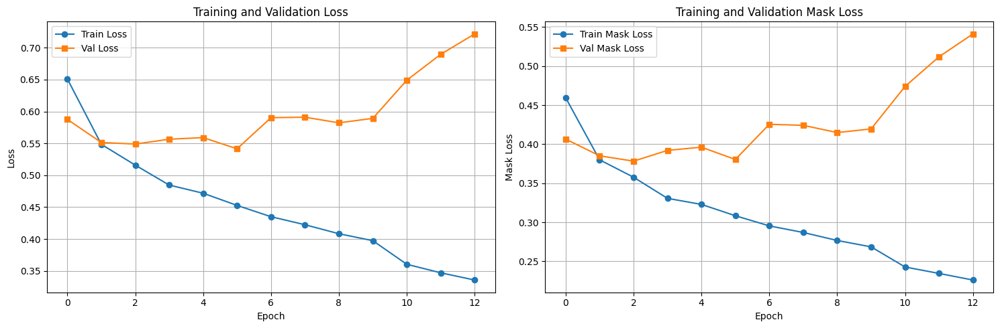

Training history saved to checkpoints/training_history.json


In [18]:
# Plot training curves
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Loss plot
axes[0].plot(history['train_loss'], label='Train Loss', marker='o')
axes[0].plot(history['val_loss'], label='Val Loss', marker='s')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()
axes[0].grid(True)

# Mask loss plot
axes[1].plot(history['train_mask_loss'], label='Train Mask Loss', marker='o')
axes[1].plot(history['val_mask_loss'], label='Val Mask Loss', marker='s')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Mask Loss')
axes[1].set_title('Training and Validation Mask Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(os.path.join(output_dir, 'training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

# Save training history
with open(os.path.join(output_dir, 'training_history.json'), 'w') as f:
    json.dump(history, f, indent=2)

print(f"Training history saved to {output_dir}/training_history.json")


## 11. Visualize Predictions


Generating predictions on validation set...


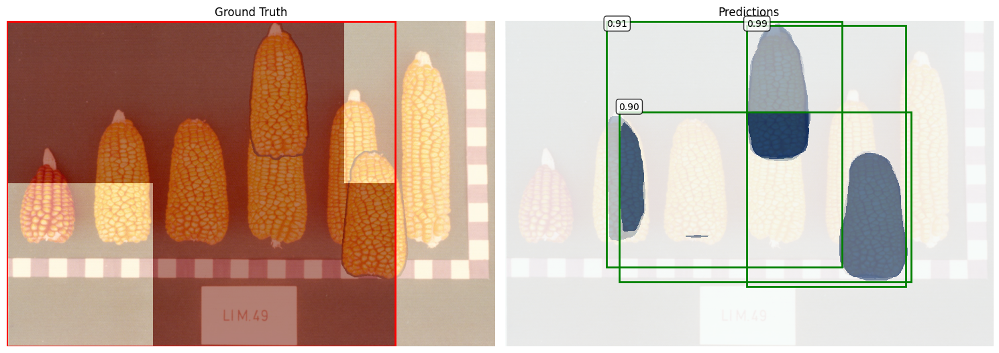

Sample 480: GT masks=1, Predictions=3, Image size=1000x666


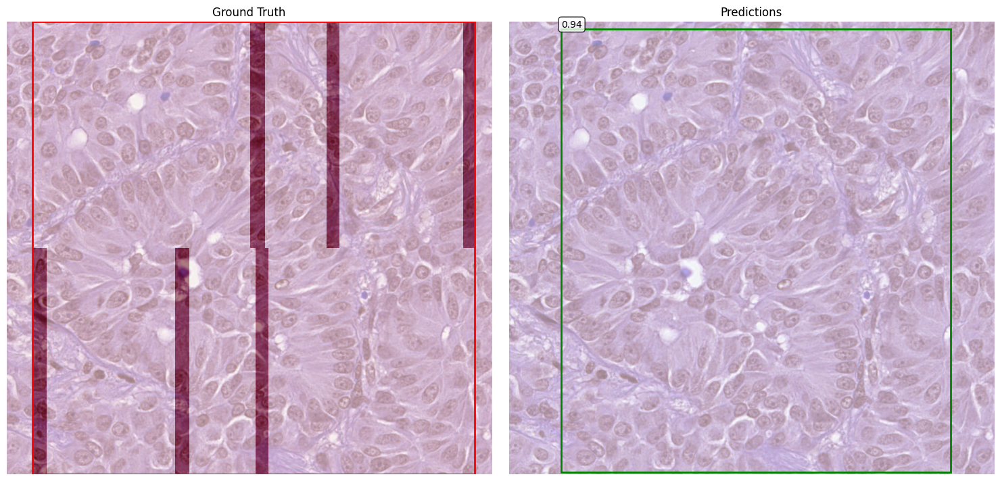

Sample 373: GT masks=1, Predictions=1, Image size=910x850


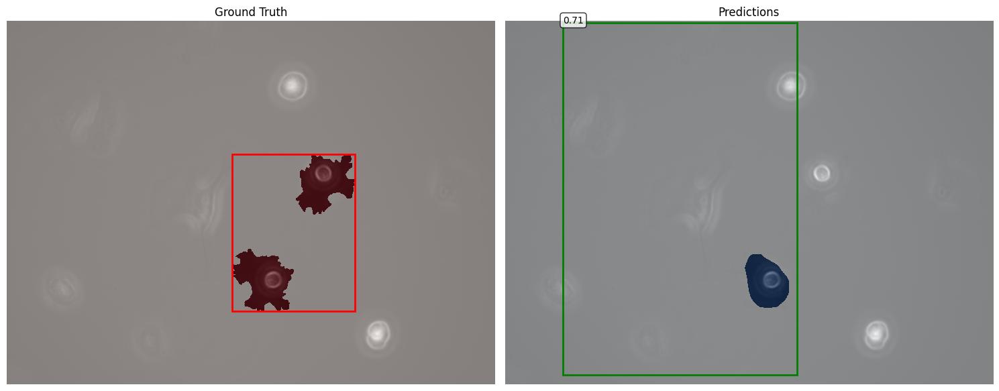

Sample 13: GT masks=1, Predictions=1, Image size=2568x1912


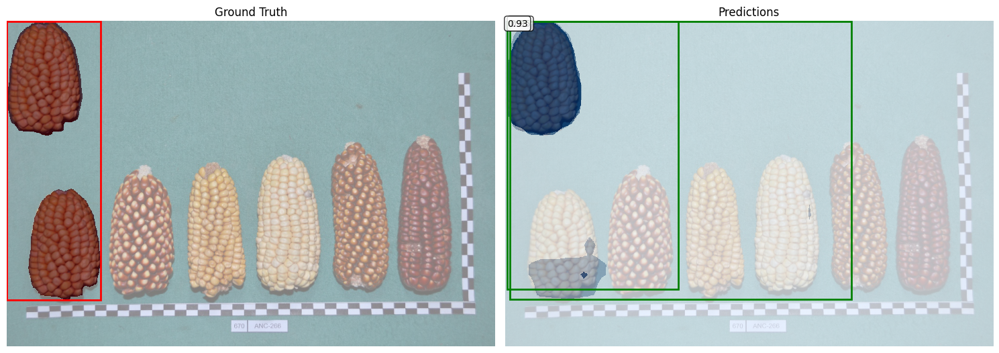

Sample 154: GT masks=1, Predictions=2, Image size=1000x666


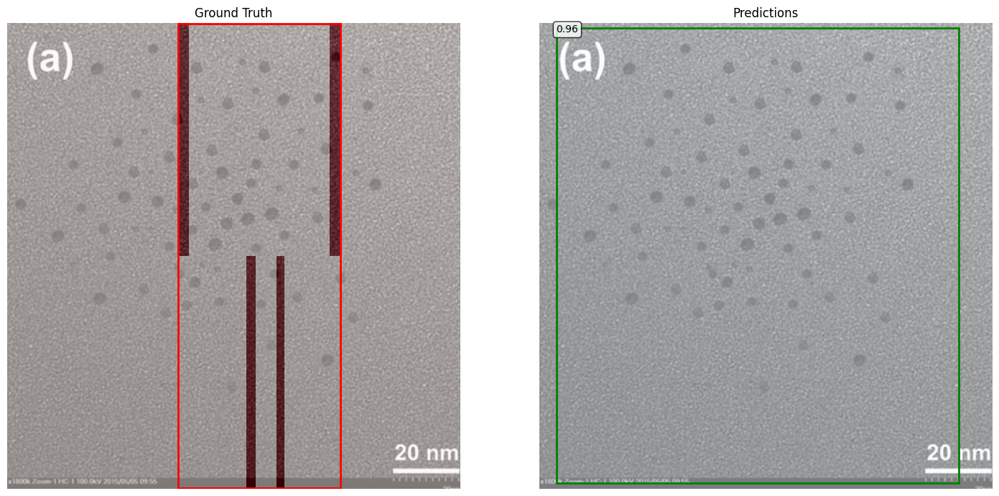

Sample 310: GT masks=1, Predictions=1, Image size=512x526


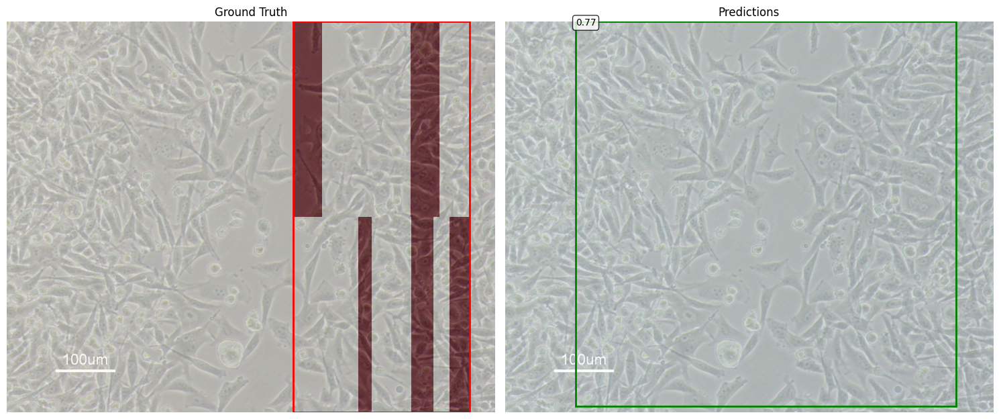

Sample 159: GT masks=1, Predictions=1, Image size=1280x1024


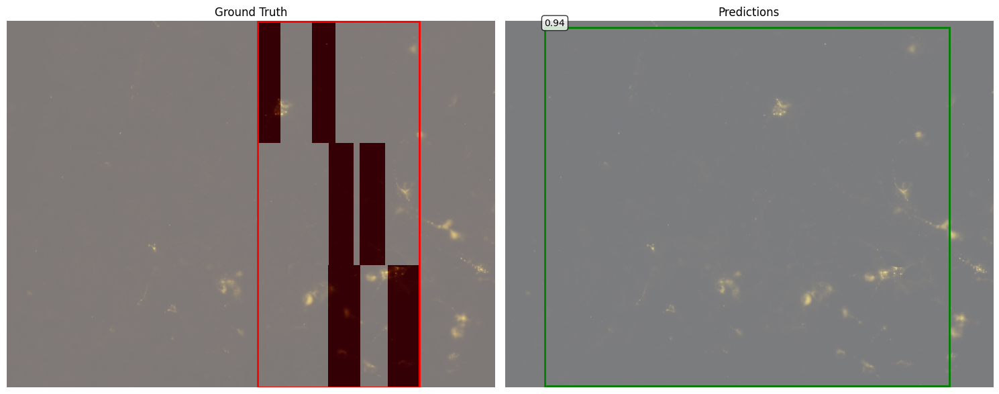

Sample 79: GT masks=1, Predictions=1, Image size=1600x1200


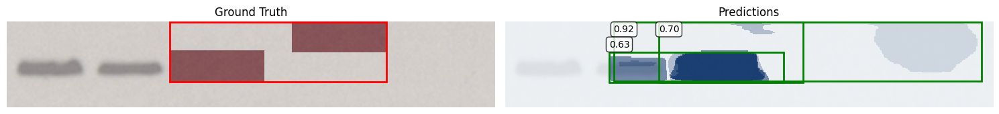

Sample 300: GT masks=1, Predictions=3, Image size=483x85


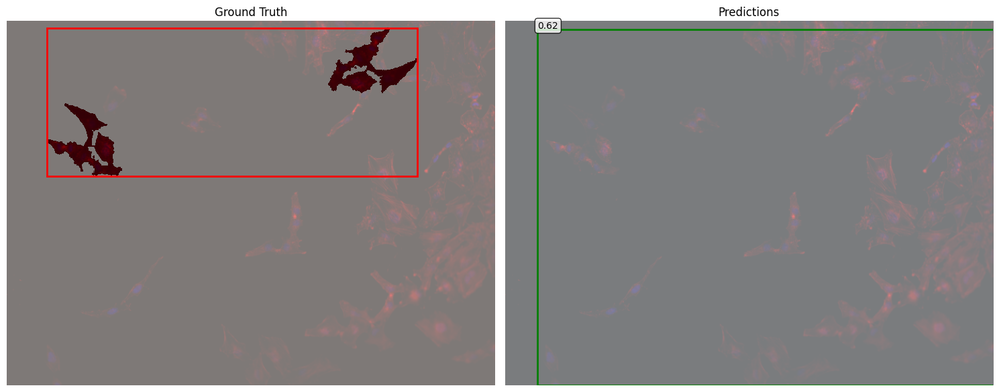

Sample 185: GT masks=1, Predictions=1, Image size=696x520


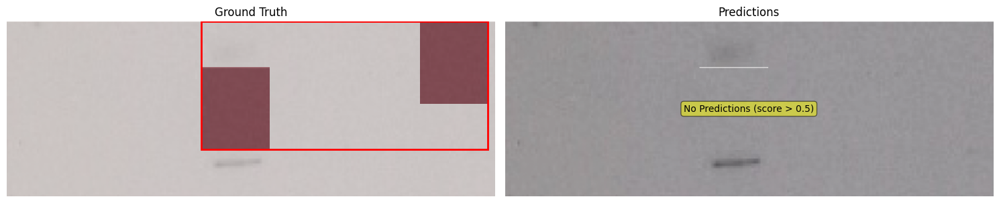

Sample 134: GT masks=1, Predictions=0, Image size=518x186
Saved 10 predictions to predictions/


In [19]:
def visualize_predictions(model, dataset, device, num_samples=5, save_dir='predictions'):
    """Visualize model predictions on validation images."""
    os.makedirs(save_dir, exist_ok=True)
    model.eval()

    # Get random samples
    indices = np.random.choice(len(dataset), min(num_samples, len(dataset)), replace=False)

    for idx in indices:
        image, target = dataset[idx]
        
        # Get original image dimensions for resizing predictions
        img_height, img_width = image.shape[1], image.shape[2]

        with torch.no_grad():
            prediction = model([image.to(device)])[0]

        # Convert image back for visualization
        img_np = image.permute(1, 2, 0).cpu().numpy()
        img_np = (img_np * 255).astype(np.uint8)

        fig, axes = plt.subplots(1, 2, figsize=(15, 7))

        # Ground truth
        axes[0].imshow(img_np)
        axes[0].set_title('Ground Truth')
        axes[0].axis('off')
        
        if target['masks'].shape[0] > 0:
            # Extract ground truth mask
            mask_gt = target['masks'][0].numpy()  # Shape: (H, W)
            
            # Ensure mask matches image dimensions
            if mask_gt.shape != (img_height, img_width):
                from PIL import Image as PILImage
                mask_gt = np.array(PILImage.fromarray(mask_gt).resize(
                    (img_width, img_height), PILImage.NEAREST
                ))
            
            # Convert to boolean for proper overlay
            mask_gt_bool = mask_gt.astype(bool) if mask_gt.dtype != bool else mask_gt
            
            # Overlay mask
            axes[0].imshow(mask_gt_bool, alpha=0.5, cmap='Reds', interpolation='nearest')
            
            if target['boxes'].shape[0] > 0:
                box_gt = target['boxes'][0].numpy()
                # Ensure box coordinates are within image bounds
                box_gt = np.clip(box_gt, 0, [img_width, img_height, img_width, img_height])
                rect = patches.Rectangle(
                    (box_gt[0], box_gt[1]), 
                    box_gt[2] - box_gt[0], 
                    box_gt[3] - box_gt[1],
                    linewidth=2, edgecolor='red', facecolor='none'
                )
                axes[0].add_patch(rect)
        else:
            axes[0].text(0.5, 0.5, 'No Ground Truth Mask', 
                        transform=axes[0].transAxes, ha='center', va='center',
                        bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.5))

        # Predictions
        axes[1].imshow(img_np)
        axes[1].set_title('Predictions')
        axes[1].axis('off')

        # Draw predictions
        scores = prediction['scores'].cpu().numpy()
        masks = prediction['masks'].cpu().numpy()  # Shape: (N, 1, H_pred, W_pred)
        boxes = prediction['boxes'].cpu().numpy()
        
        num_detections = 0
        for i in range(len(scores)):
            if scores[i] > 0.5:  # Confidence threshold
                num_detections += 1
                
                # Resize predicted mask to match original image dimensions
                pred_mask = masks[i, 0]  # Shape: (H_pred, W_pred)
                
                # Resize mask to original image size
                from PIL import Image as PILImage
                pred_mask_resized = np.array(
                    PILImage.fromarray((pred_mask * 255).astype(np.uint8)).resize(
                        (img_width, img_height), PILImage.NEAREST
                    )
                ) / 255.0
                
                # Threshold the resized mask
                mask_bool = pred_mask_resized > 0.5
                
                # Overlay mask
                axes[1].imshow(mask_bool, alpha=0.5, cmap='Blues', interpolation='nearest')

                # Draw bounding box
                box = boxes[i]
                # Ensure box coordinates are within image bounds
                box = np.clip(box, 0, [img_width, img_height, img_width, img_height])
                rect = patches.Rectangle(
                    (box[0], box[1]), 
                    box[2] - box[0], 
                    box[3] - box[1],
                    linewidth=2, edgecolor='green', facecolor='none'
                )
                axes[1].add_patch(rect)
                axes[1].text(box[0], max(box[1] - 5, 10), f'{scores[i]:.2f}',
                           bbox=dict(boxstyle='round', facecolor='white', alpha=0.8),
                           fontsize=10)
        
        if num_detections == 0:
            axes[1].text(0.5, 0.5, 'No Predictions (score > 0.5)', 
                        transform=axes[1].transAxes, ha='center', va='center',
                        bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.5))

        plt.tight_layout()
        plt.savefig(os.path.join(save_dir, f'prediction_{idx}.png'), dpi=150, bbox_inches='tight')
        plt.show()
        
        # Print debug info
        print(f"Sample {idx}: GT masks={target['masks'].shape[0]}, "
              f"Predictions={num_detections}, Image size={img_width}x{img_height}")

    print(f"Saved {len(indices)} predictions to {save_dir}/")

# Generate predictions
print("Generating predictions on validation set...")
visualize_predictions(model, val_dataset, device, num_samples=10)


## 11.1. Load Best Model for Evaluation

Load the best model checkpoint (based on validation loss) for predictions and inference.


In [ ]:
# Load the best model checkpoint for inference
best_model_path = os.path.join(output_dir, 'best_model.pth')

if os.path.exists(best_model_path):
    print(f"Loading best model from {best_model_path}...")
    checkpoint = torch.load(best_model_path, map_location=device)
    
    # Load model weights
    model.load_state_dict(checkpoint['model_state_dict'])
    
    # Optionally load optimizer state if continuing training
    # optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    
    best_epoch = checkpoint.get('epoch', 'unknown')
    best_val_loss = checkpoint.get('val_loss', 'unknown')
    
    print(f"✓ Loaded best model from epoch {best_epoch}")
    print(f"  Best validation loss: {best_val_loss:.4f}")
    print(f"  Model ready for inference!")
else:
    print(f"⚠️  Best model checkpoint not found at {best_model_path}")
    print(f"  Using current model state instead.")
    
model.eval()  # Set to evaluation mode


## 12. Inference on New Images

Example code for running inference on new images:


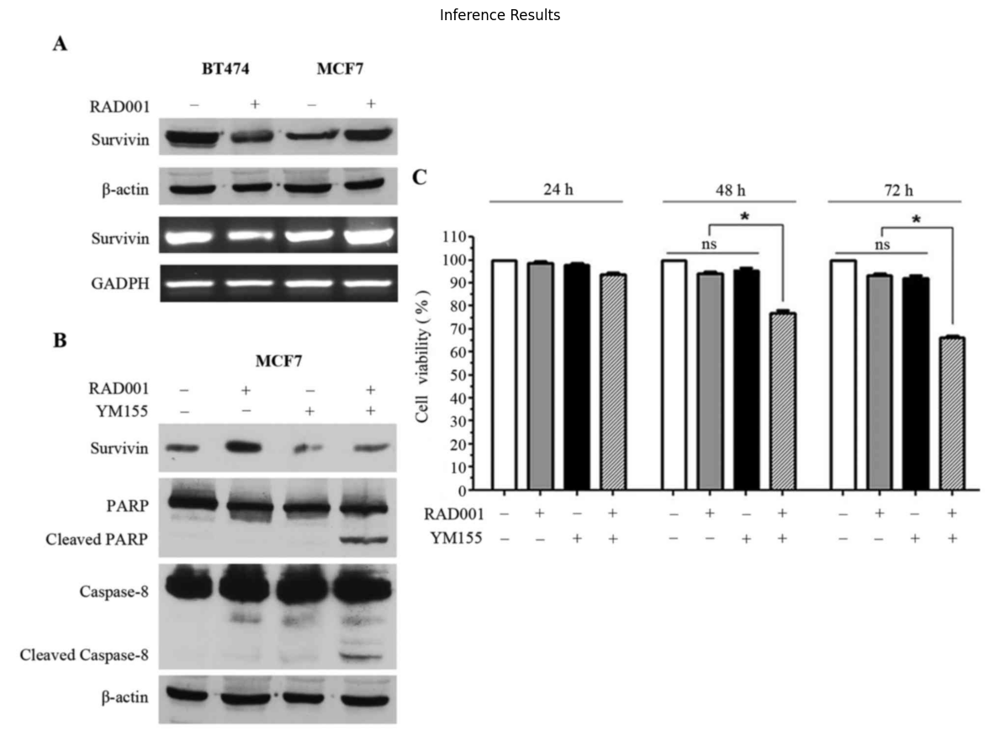

Detected 0 forged region(s) with confidence > 0.5


In [ ]:
# Model is already loaded and set to eval mode in previous cell
# Using best model checkpoint for inference

# Example: Load a test image
test_image_path = os.path.join(DATA_DIR, "test_images", "45.png")  # Update with your test image

if os.path.exists(test_image_path):
    # Load and preprocess image
    image = Image.open(test_image_path).convert('RGB')
    transform = transforms.ToTensor()
    image_tensor = transform(image).unsqueeze(0).to(device)

    # Run inference
    with torch.no_grad():
        predictions = model(image_tensor)

    # Extract results
    pred = predictions[0]
    scores = pred['scores'].cpu().numpy()
    masks = pred['masks'].cpu().numpy()
    boxes = pred['boxes'].cpu().numpy()

    # Visualize
    fig, ax = plt.subplots(1, 1, figsize=(12, 12))
    img_np = np.array(image)
    ax.imshow(img_np)
    ax.set_title('Inference Results')
    ax.axis('off')

    # Draw predictions
    for i in range(len(scores)):
        if scores[i] > 0.5:  # Confidence threshold
            mask = masks[i, 0] > 0.5
            ax.imshow(mask, alpha=0.5, cmap='Blues')

            # Draw bounding box
            box = boxes[i]
            rect = patches.Rectangle(
                (box[0], box[1]), box[2] - box[0], box[3] - box[1],
                linewidth=2, edgecolor='green', facecolor='none'
            )
            ax.add_patch(rect)
            ax.text(box[0], box[1], f'Forged: {scores[i]:.2f}',
                   bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

    plt.tight_layout()
    plt.show()

    print(f"Detected {len(scores[scores > 0.5])} forged region(s) with confidence > 0.5")
else:
    print(f"Test image not found at: {test_image_path}")
    print("Update the path to test on your own images")
